In [32]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [66]:
file_path = "Sample - Superstore 2.csv"

In [67]:
df = pd.read_csv(file_path, encoding="latin1")

In [68]:
print("Dataset Shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Dataset Shape (rows, columns): (9994, 21)

First 5 rows:
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product

In [69]:
print("\n✅ Missing Values in each column:",df.isnull().sum())
print("\n✅ Number of Duplicate Rows:", df.duplicated().sum())


✅ Missing Values in each column: Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

✅ Number of Duplicate Rows: 0


In [121]:
cols_to_drop = ["Row ID", "Order ID", "Customer ID","Ship Mode","Month","Ship Date", "Postal Code", "Country" , "Product ID" , "Customer Name"]
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

In [122]:
df.head()

,Order Date,Segment,City,State,Region,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin (%),Profit Status,Discount Bucket,Sales Bucket,Month-Year
0,2016-11-08,Consumer,Henderson,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,16.00,Profit,No Discount,100-500,2016-11
1,2016-11-08,Consumer,Henderson,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,30.00,Profit,No Discount,500-1000,2016-11
2,2016-06-12,Corporate,Los Angeles,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,47.00,Profit,No Discount,0-100,2016-06
3,2015-10-11,Consumer,Fort Lauderdale,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-40.00,Loss,Medium Discount,500-1000,2015-10
4,2015-10-11,Consumer,Fort Lauderdale,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,11.25,Profit,Low Discount,0-100,2015-10


In [78]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])


In [79]:
df.head()

,Order Date,Ship Date,Ship Mode,Segment,City,State,Region,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,2016-06-12,2016-06-16,Second Class,Corporate,Los Angeles,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [80]:
text_cols = ["Segment","Region","Category","Sub-Category","City","State","Ship Mode"]
for col in text_cols:
    df[col] = df[col].astype(str).str.strip().str.title()


In [82]:
df.head()

,Order Date,Ship Date,Ship Mode,Segment,City,State,Region,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,2016-06-12,2016-06-16,Second Class,Corporate,Los Angeles,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [83]:
num_cols = ["Sales", "Quantity", "Discount", "Profit"]

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce") 

In [84]:
df = df[(df["Sales"] > 0) & (df["Quantity"] > 0)]

In [85]:
#Profit Margin (%)
# Formula: (Profit / Sales) * 100
df["Profit Margin (%)"] = np.where(df["Sales"] != 0,(df["Profit"] / df["Sales"]) * 100,0)


In [86]:
#Profit Status -> Profit or Loss
df["Profit Status"] = df["Profit"].apply(lambda x: "Profit" if x >= 0 else "Loss")


In [87]:
df.head()

,Order Date,Ship Date,Ship Mode,Segment,City,State,Region,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin (%),Profit Status
0,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,16.00,Profit
1,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,30.00,Profit
2,2016-06-12,2016-06-16,Second Class,Corporate,Los Angeles,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,47.00,Profit
3,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-40.00,Loss
4,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,11.25,Profit


In [88]:
#Discount Bucket -> Categorize discount
def discount_bucket(discount):
    if discount == 0:
        return "No Discount"
    elif discount <= 0.2:
        return "Low Discount"
    elif discount <= 0.5:
        return "Medium Discount"
    else:
        return "High Discount"

df["Discount Bucket"] = df["Discount"].apply(discount_bucket)


In [89]:
#Sales Bucket -> Categorize Sales range
df["Sales Bucket"] = pd.cut(df["Sales"],
                            bins=[0, 100, 500, 1000, 5000, df["Sales"].max()],
                            labels=["0-100", "100-500", "500-1000",
                                    "1000-5000", "5000+"])



In [90]:
df.head()

,Order Date,Ship Date,Ship Mode,Segment,City,State,Region,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin (%),Profit Status,Discount Bucket,Sales Bucket
0,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,16.00,Profit,No Discount,100-500
1,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,30.00,Profit,No Discount,500-1000
2,2016-06-12,2016-06-16,Second Class,Corporate,Los Angeles,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,47.00,Profit,No Discount,0-100
3,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-40.00,Loss,Medium Discount,500-1000
4,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,11.25,Profit,Low Discount,0-100


In [124]:
df.to_csv("cleaned_SampleSuperstore_dataset.csv", index=False)

In [92]:
#Overall Sales and Profit
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))

Total Sales: 2297200.86
Total Profit: 286397.02


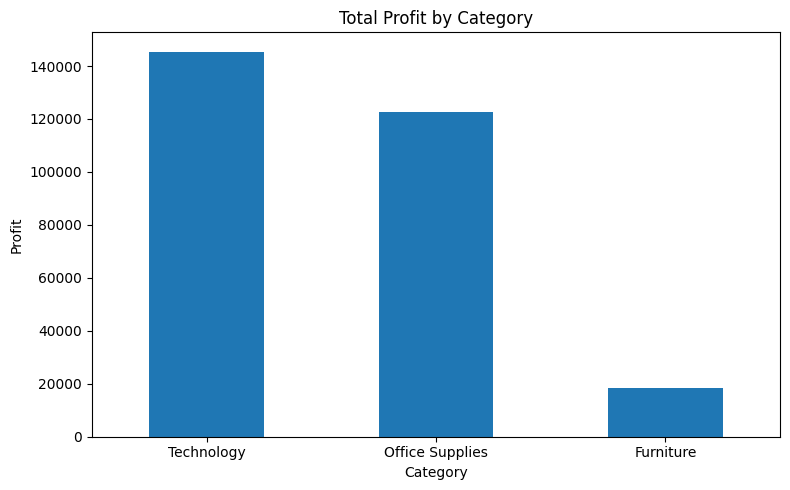

In [93]:
#Profit by Category
profit_by_category = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
profit_by_category.plot(kind="bar")
plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


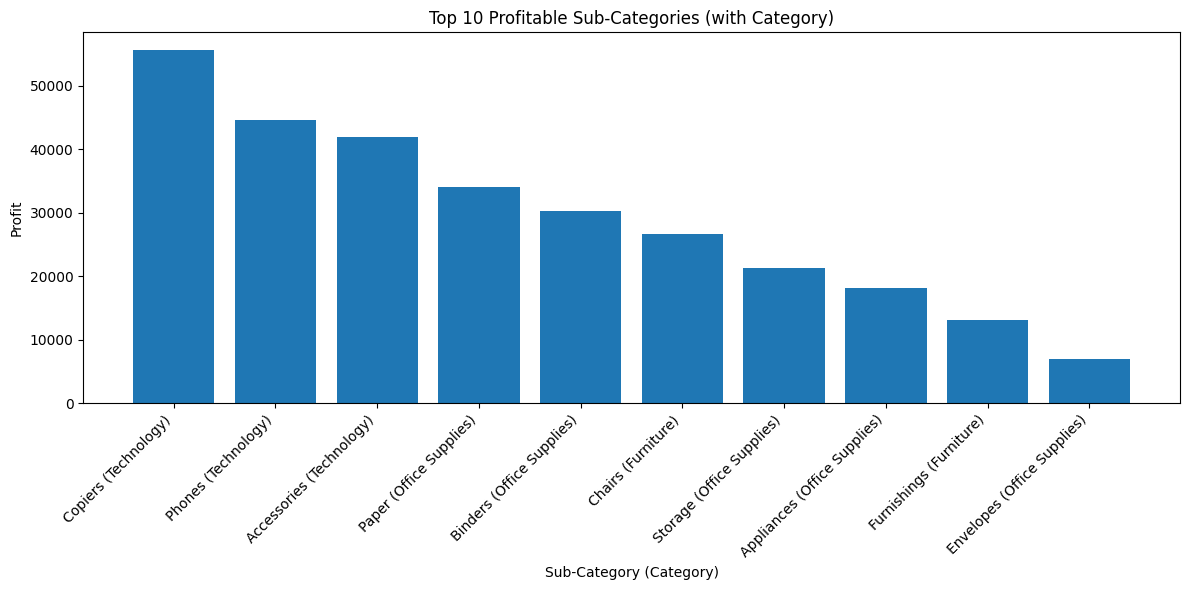

In [94]:
# Group by Sub-Category AND Category, then calculate total profit
profit_by_subcat = (
    df.groupby(["Sub-Category", "Category"])["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Create labels like: "Sub-Category (Category)"
labels = [f"{subcat} ({cat})" for subcat, cat in profit_by_subcat.index]

plt.figure(figsize=(12,6))
plt.bar(labels, profit_by_subcat.values)

plt.title("Top 10 Profitable Sub-Categories (with Category)")
plt.xlabel("Sub-Category (Category)")
plt.ylabel("Profit")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


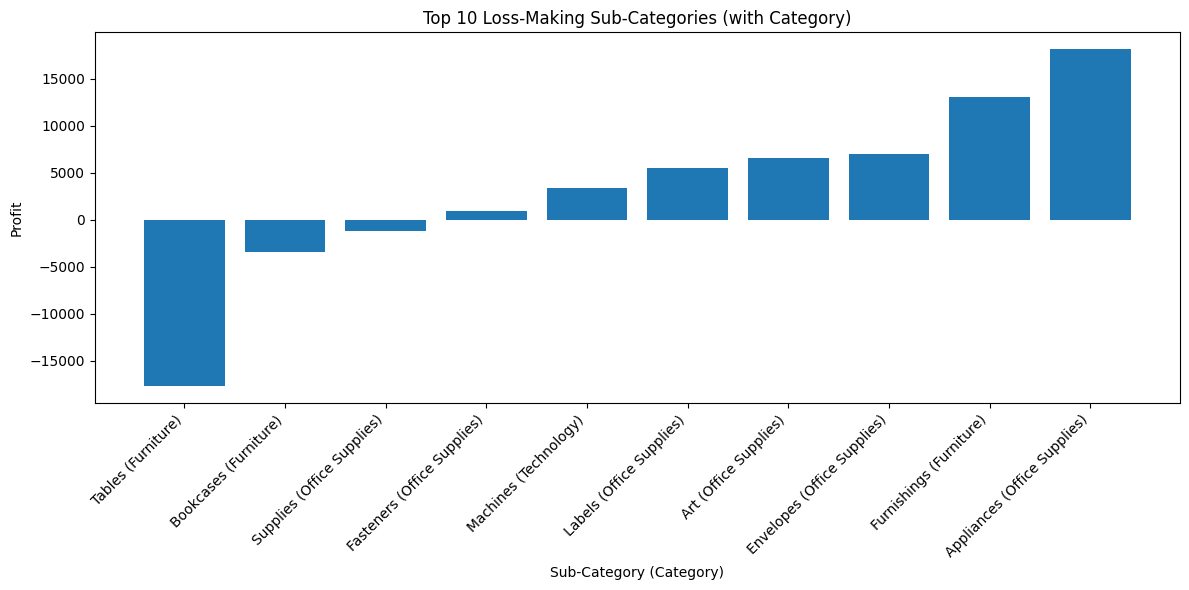

In [95]:
# Group by Sub-Category AND Category, then calculate total profit (ascending for losses)
loss_by_subcat = (
    df.groupby(["Sub-Category", "Category"])["Profit"]
    .sum()
    .sort_values()
    .head(10)
)

labels = [f"{subcat} ({cat})" for subcat, cat in loss_by_subcat.index]

plt.figure(figsize=(12,6))
plt.bar(labels, loss_by_subcat.values)

plt.title("Top 10 Loss-Making Sub-Categories (with Category)")
plt.xlabel("Sub-Category (Category)")
plt.ylabel("Profit")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


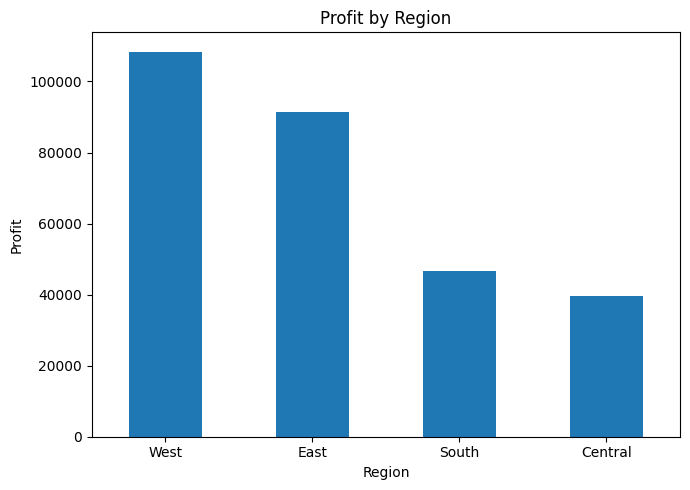

In [96]:
profit_by_region = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

plt.figure(figsize=(7,5))
profit_by_region.plot(kind="bar")
plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

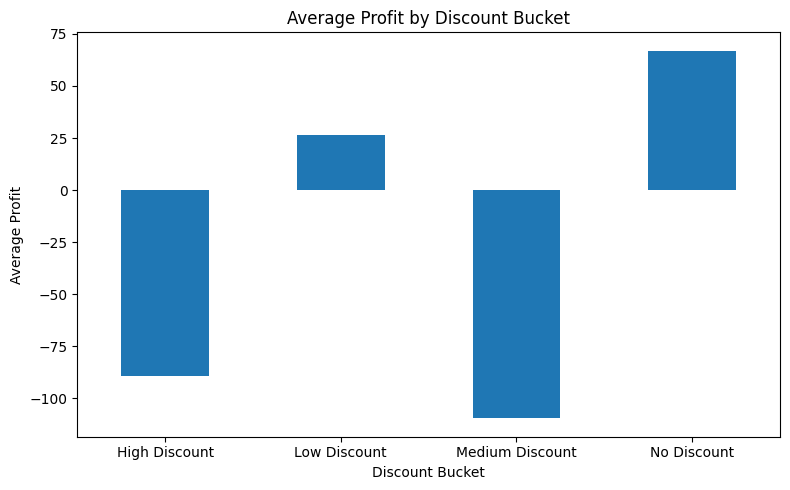

In [97]:
discount_profit = df.groupby("Discount Bucket")["Profit"].mean()

plt.figure(figsize=(8,5))
discount_profit.plot(kind="bar")
plt.title("Average Profit by Discount Bucket")
plt.xlabel("Discount Bucket")
plt.ylabel("Average Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

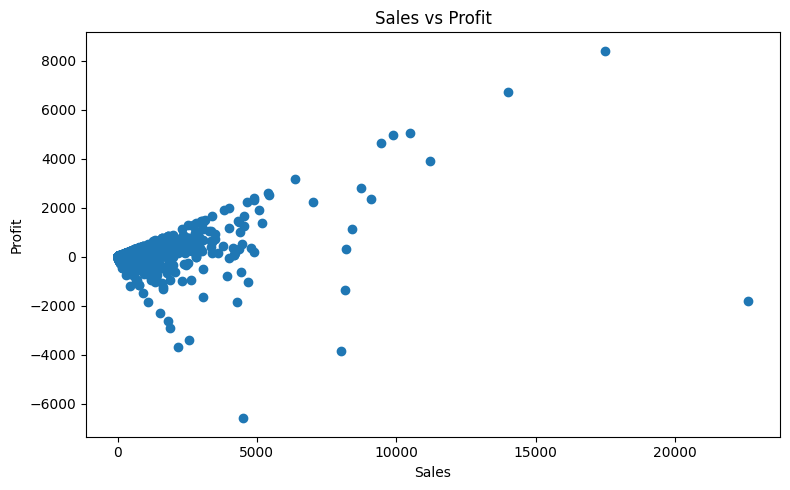

In [98]:
plt.figure(figsize=(8,5))
plt.scatter(df["Sales"], df["Profit"])
plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()


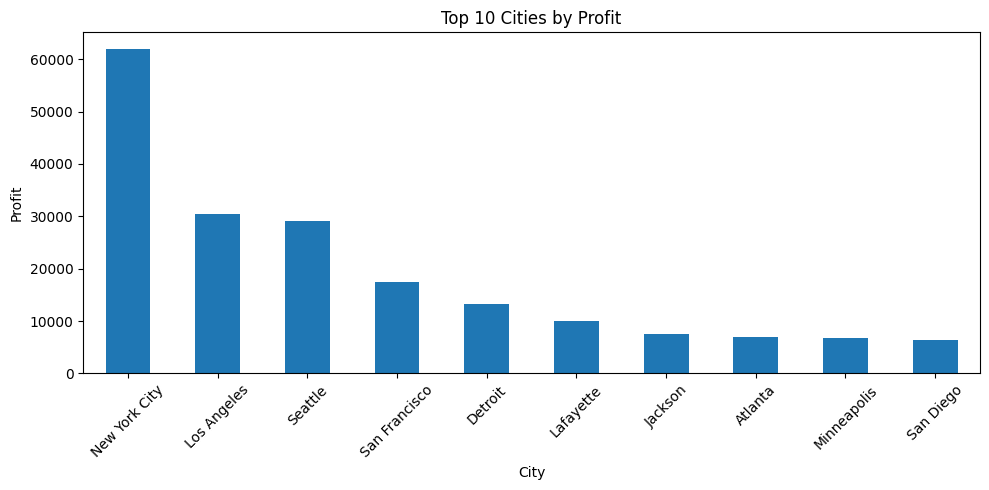

In [99]:
top_cities = df.groupby("City")["Profit"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
top_cities.plot(kind="bar")
plt.title("Top 10 Cities by Profit")
plt.xlabel("City")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [100]:
best_profit_cat = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
print("\nMost Profitable Categories:\n", best_profit_cat)

best_profit_subcat = df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False).head(10)
print("\nTop 10 Most Profitable Sub-Categories:\n", best_profit_subcat)



Most Profitable Categories:
 Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64

Top 10 Most Profitable Sub-Categories:
 Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Chairs         26590.1663
Storage        21278.8264
Appliances     18138.0054
Furnishings    13059.1436
Envelopes       6964.1767
Name: Profit, dtype: float64


In [101]:
loss_cat = df.groupby("Category")["Profit"].sum().idxmin()
print("Loss-Making Category:", loss_cat)


Loss-Making Category: Furniture


In [102]:
top_region = df.groupby("Region")["Profit"].sum().idxmax()
print("Most Profitable Region:", top_region)


Most Profitable Region: West


In [103]:
loss_region = df.groupby("Region")["Profit"].sum().idxmin()
print("Loss-Making Region:", loss_region)


Loss-Making Region: Central


In [104]:
top_subcat = df.groupby("Sub-Category")["Profit"].sum().idxmax()
print("Top Profitable Sub-Category:", top_subcat)


Top Profitable Sub-Category: Copiers


In [105]:
loss_subcat = df.groupby("Sub-Category")["Profit"].sum().idxmin()
print("Highest Loss Sub-Category:", loss_subcat)


Highest Loss Sub-Category: Tables


In [106]:
discount_impact = df.groupby("Discount Bucket")["Profit"].mean()
print("\nAverage Profit by Discount Level:")
print(discount_impact)



Average Profit by Discount Level:
Discount Bucket
High Discount      -89.438144
Low Discount        26.501571
Medium Discount   -109.528873
No Discount         66.900292
Name: Profit, dtype: float64


In [107]:
top_segment = df.groupby("Segment")["Profit"].sum().idxmax()
print("Most Profitable Customer Segment:", top_segment)


Most Profitable Customer Segment: Consumer


In [108]:
segment_sales_profit = df.groupby("Segment")[["Sales", "Profit"]].sum().sort_values(by="Profit", ascending=False)
print("Customer Segment Performance:\n", segment_sales_profit)

Customer Segment Performance:
                     Sales       Profit
Segment                               
Consumer     1.161401e+06  134119.2092
Corporate    7.061464e+05   91979.1340
Home Office  4.296531e+05   60298.6785


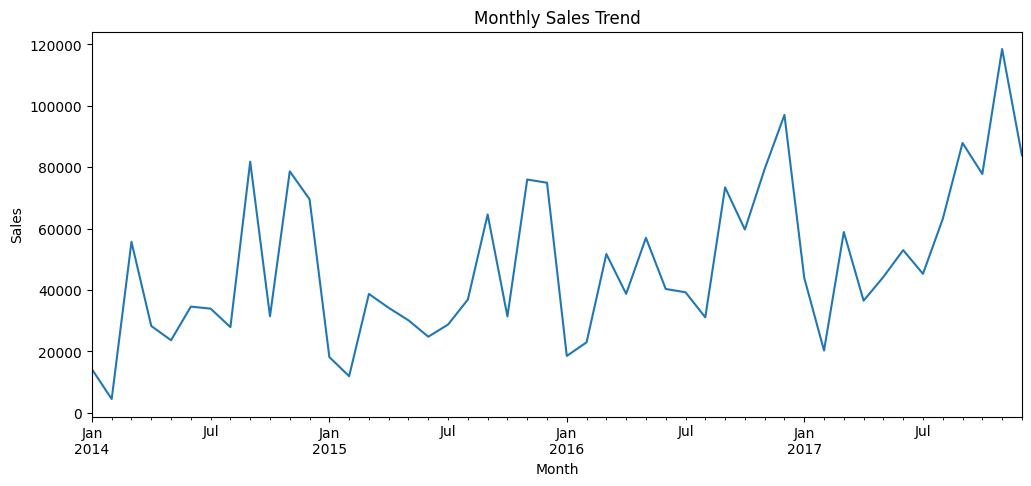

In [110]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Month"] = df["Order Date"].dt.to_period("M")

monthly_trend = df.groupby("Month")["Sales"].sum()

monthly_trend.plot(figsize=(12,5), title="Monthly Sales Trend")
plt.ylabel("Sales")
plt.show()


In [112]:
df.head()

,Order Date,Ship Date,Ship Mode,Segment,City,State,Region,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin (%),Profit Status,Discount Bucket,Sales Bucket,Month
0,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,16.00,Profit,No Discount,100-500,2016-11
1,2016-11-08,2016-11-11,Second Class,Consumer,Henderson,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,30.00,Profit,No Discount,500-1000,2016-11
2,2016-06-12,2016-06-16,Second Class,Corporate,Los Angeles,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,47.00,Profit,No Discount,0-100,2016-06
3,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-40.00,Loss,Medium Discount,500-1000,2015-10
4,2015-10-11,2015-10-18,Standard Class,Consumer,Fort Lauderdale,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,11.25,Profit,Low Discount,0-100,2015-10


In [116]:
df["Month-Year"] = df["Order Date"].dt.to_period("M")
monthly_sales = df.groupby("Month-Year")["Sales"].sum()

print(monthly_sales.head())



Month-Year
2014-01    14236.895
2014-02     4519.892
2014-03    55691.009
2014-04    28295.345
2014-05    23648.287
Freq: M, Name: Sales, dtype: float64


In [123]:
df.head()

,Order Date,Segment,City,State,Region,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin (%),Profit Status,Discount Bucket,Sales Bucket,Month-Year
0,2016-11-08,Consumer,Henderson,Kentucky,South,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,16.00,Profit,No Discount,100-500,2016-11
1,2016-11-08,Consumer,Henderson,Kentucky,South,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,30.00,Profit,No Discount,500-1000,2016-11
2,2016-06-12,Corporate,Los Angeles,California,West,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,47.00,Profit,No Discount,0-100,2016-06
3,2015-10-11,Consumer,Fort Lauderdale,Florida,South,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-40.00,Loss,Medium Discount,500-1000,2015-10
4,2015-10-11,Consumer,Fort Lauderdale,Florida,South,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,11.25,Profit,Low Discount,0-100,2015-10
